ejemplo visual

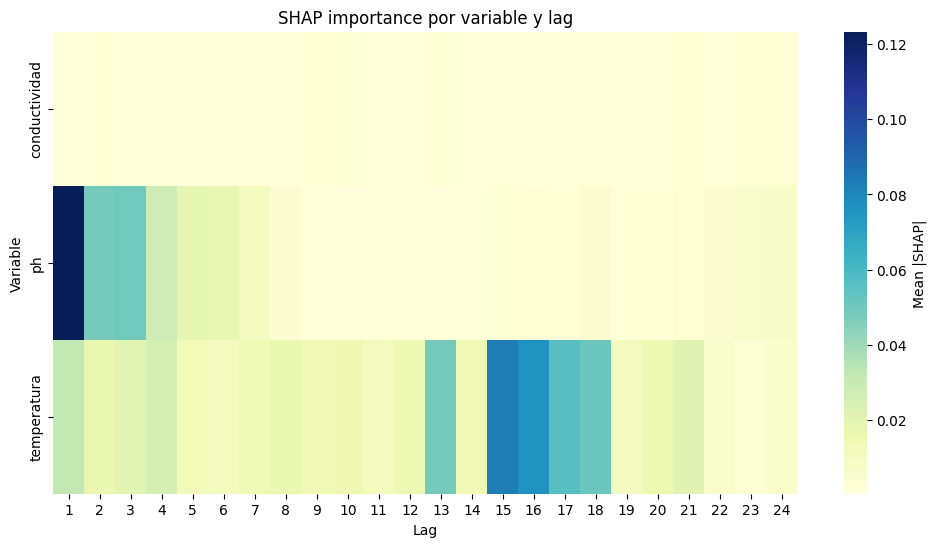

Predicción en t=2021-01-11 13:00:00
Top features que más influyeron:
  ph_lag1 -> SHAP=-0.096
  temperatura_lag15 -> SHAP=-0.088
  temperatura_lag16 -> SHAP=-0.083
  temperatura_lag17 -> SHAP=-0.063
  temperatura_lag18 -> SHAP=-0.061
  temperatura_lag1 -> SHAP=0.051
  temperatura_lag4 -> SHAP=0.048
  temperatura_lag13 -> SHAP=-0.046
  ph_lag3 -> SHAP=-0.044
  ph_lag2 -> SHAP=-0.042


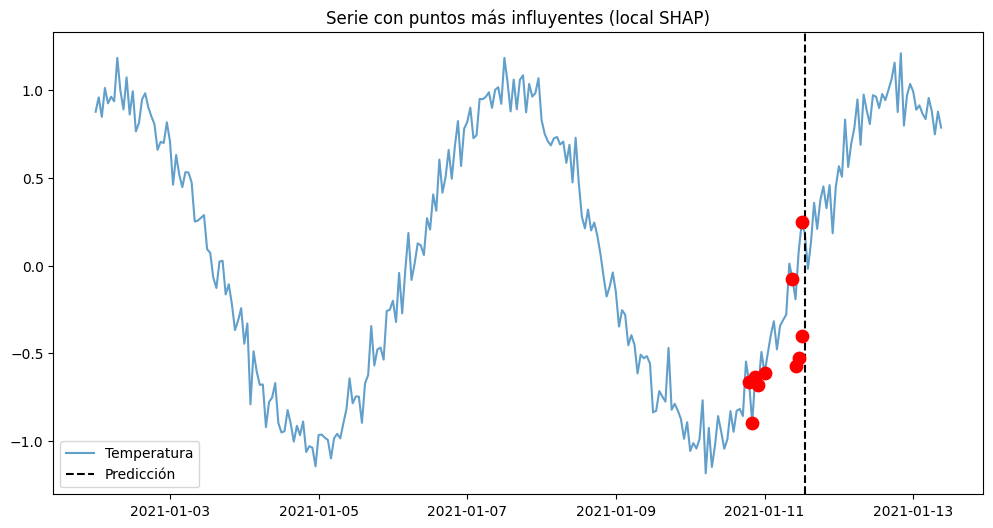

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
import shap
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# 1. Crear dataset de ejemplo (simulado)
# -----------------------------
np.random.seed(42)
n = 300
time = pd.date_range("2021-01-01", periods=n, freq="h")
df = pd.DataFrame({
    "time": time,
    "temperatura": np.sin(np.arange(n)/20) + np.random.normal(0,0.1,n),
    "ph": np.cos(np.arange(n)/15) + np.random.normal(0,0.05,n),
    "conductividad": np.random.normal(5,1,n)
})
df["target"] = df["temperatura"].shift(-1) + df["ph"].shift(-2)  # algo dependiente

# -----------------------------
# 2. Generar lags
# -----------------------------
max_lag = 24
features = []
for col in ["temperatura","ph","conductividad"]:
    for lag in range(1, max_lag+1):
        df[f"{col}_lag{lag}"] = df[col].shift(lag)
        features.append(f"{col}_lag{lag}")

df = df.dropna().reset_index(drop=True)

X = df[features]
y = df["target"]

# -----------------------------
# 3. Entrenar Random Forest
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,shuffle=False)
rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train,y_train)

# -----------------------------
# 4. SHAP values
# -----------------------------
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)

# -----------------------------
# (a) Heatmap global: importancia por variable y lag
# -----------------------------
# Promedio de SHAP absolutos
shap_abs = np.abs(shap_values).mean(axis=0)
imp = pd.DataFrame({"feature": X.columns, "importance": shap_abs})

# Separar en variable y lag
imp["variable"] = imp["feature"].apply(lambda x: x.split("_lag")[0])
imp["lag"] = imp["feature"].apply(lambda x: int(x.split("_lag")[1]))

pivot = imp.pivot(index="variable", columns="lag", values="importance")

plt.figure(figsize=(12,6))
sns.heatmap(pivot, cmap="YlGnBu", cbar_kws={'label': 'Mean |SHAP|'})
plt.title("SHAP importance por variable y lag")
plt.xlabel("Lag")
plt.ylabel("Variable")
plt.show()

# -----------------------------
# (b) Visualización local: predicción puntual
# -----------------------------
i = 10  # índice en X_test
shap_single = shap_values[i]
sample_time = df.loc[X_test.index[i],"time"]

# Ordenar las features por contribución absoluta
top_features = np.argsort(np.abs(shap_single))[-10:]  

print(f"Predicción en t={sample_time}")
print("Top features que más influyeron:")
for idx in reversed(top_features):
    print(f"  {X.columns[idx]} -> SHAP={shap_single[idx]:.3f}")

# Visualizar sobre la serie original (ejemplo con temperatura)
plt.figure(figsize=(12,6))
plt.plot(df["time"], df["temperatura"], label="Temperatura", alpha=0.7)

# Resaltar los lags más influyentes en esa predicción
for idx in top_features:
    feat = X.columns[idx]
    var, lag = feat.split("_lag")
    lag = int(lag)
    t_point = sample_time - pd.Timedelta(hours=lag)
    val = df.loc[df["time"]==t_point,var].values[0]
    plt.scatter(t_point, val, color="red", s=80, zorder=5)

plt.axvline(sample_time, color="black", linestyle="--", label="Predicción")
plt.legend()
plt.title("Serie con puntos más influyentes (local SHAP)")
plt.show()
